# EEGMMIDB resting-state rollout forecast

This notebook displays all five methods in the fixed S029 R02 experiment at every rollout step from 1 to 40. One model step is computed from the stored lag as 16/160 = 0.1 s; the four-second endpoint is therefore step 40. The result is one continuous 15–19 s boundary rollout, so no replicate uncertainty band is available.

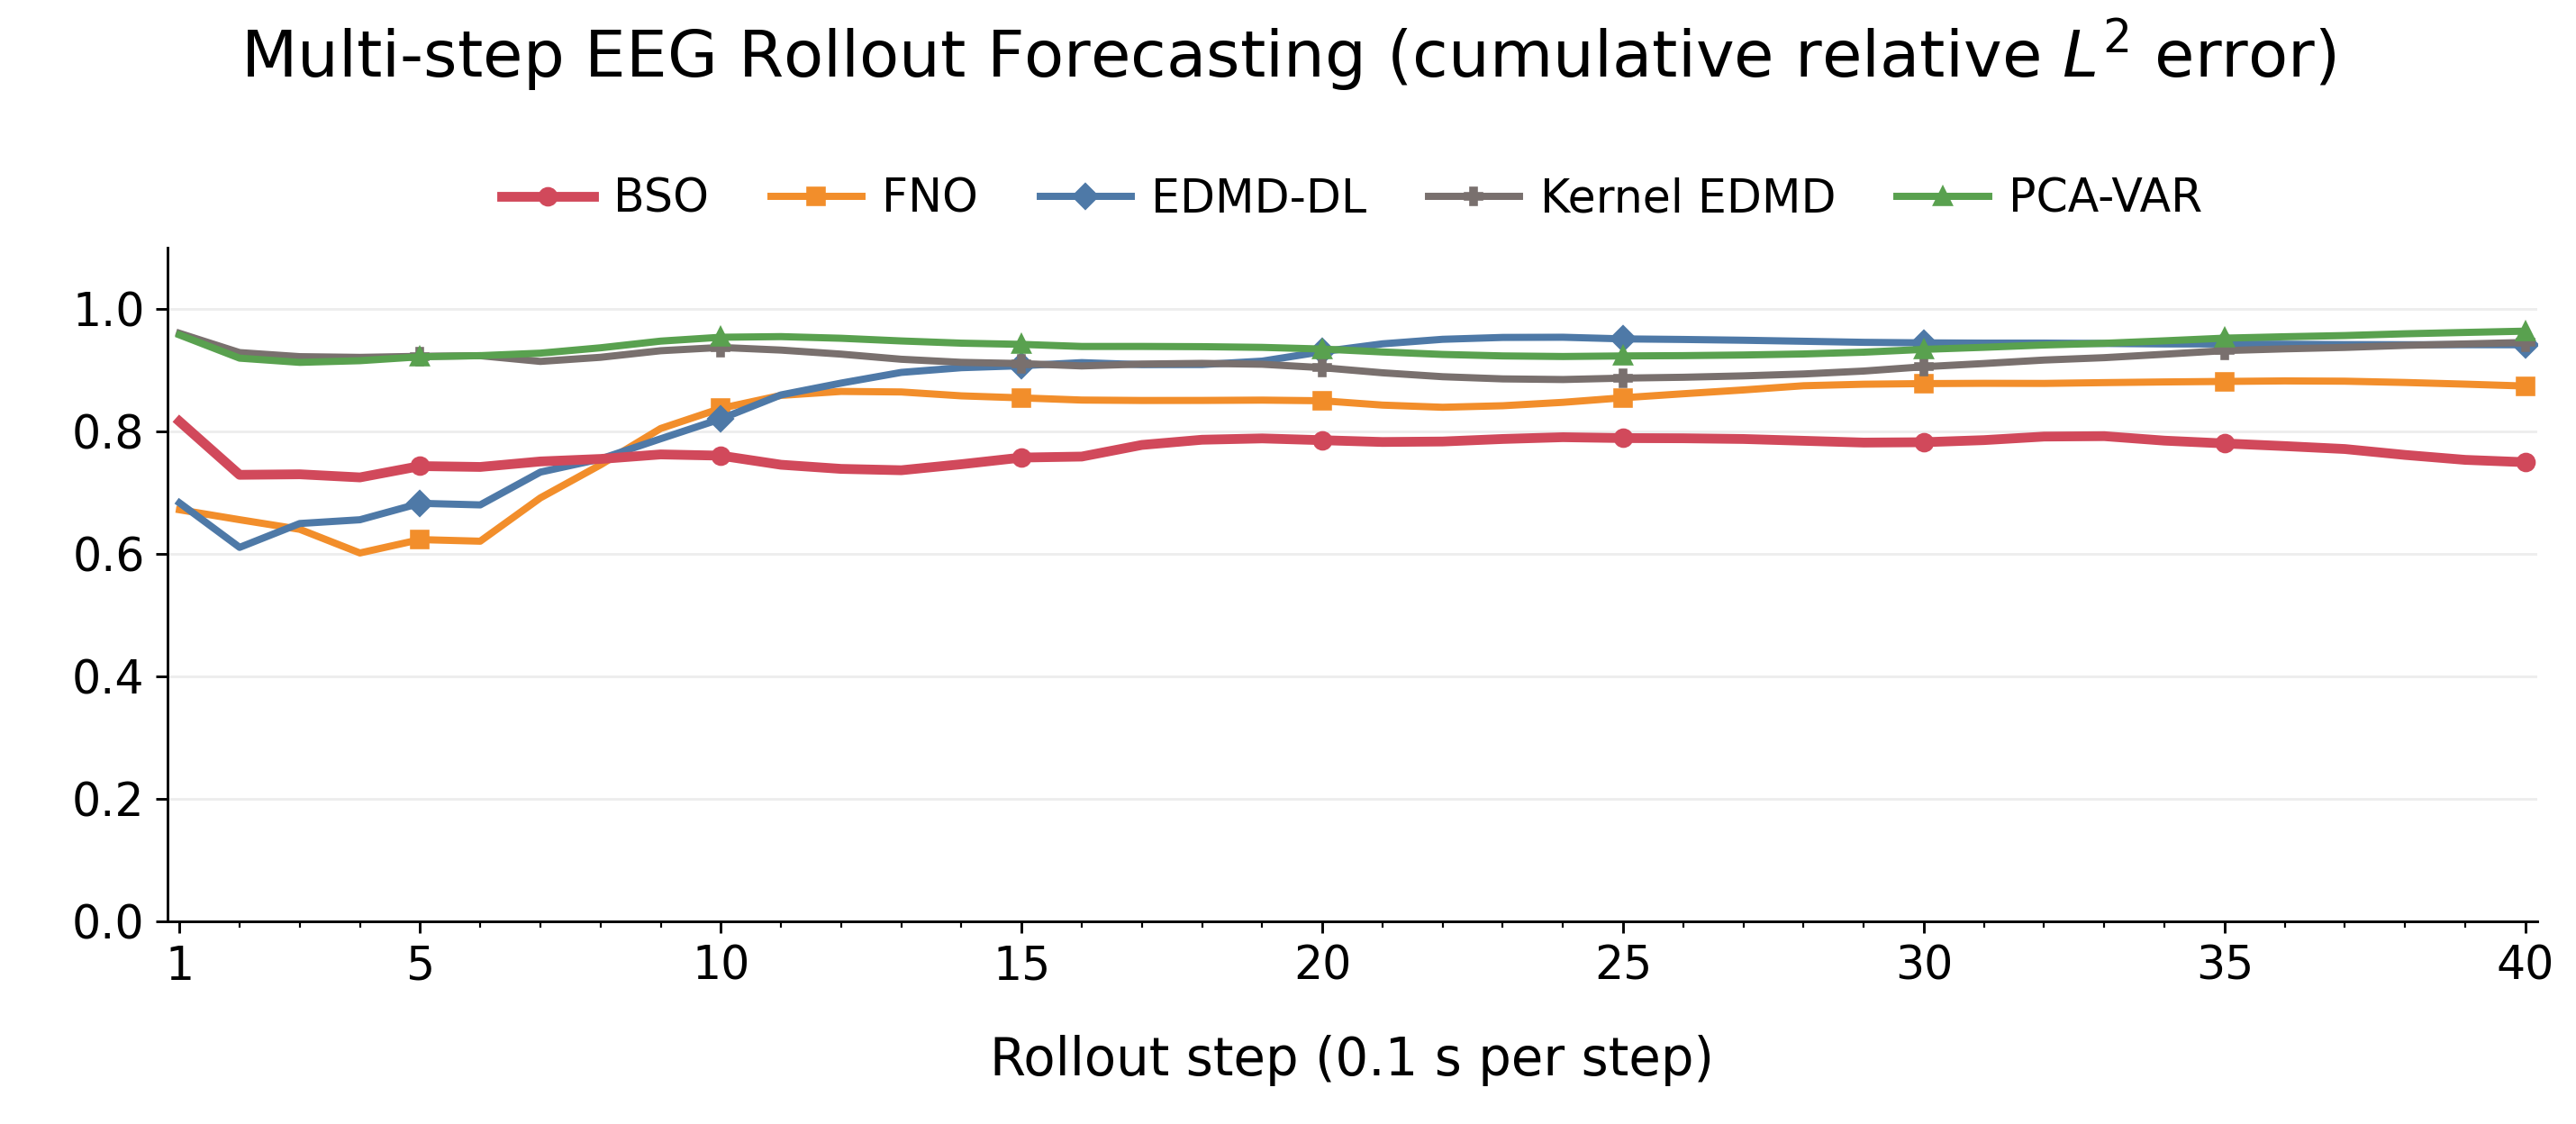


Figure caption:
Cumulative relative $L^2$ error for a four-second rollout treated as autonomous on the S029R02 eyes-closed resting EEG record. Each step advances 0.1 seconds, and all methods use the same 15--19 second forecast window. BSO has the lowest step-40 error, 14.219% below direct FNO; the result covers one subject, one run, and one rollout.


### Four-second endpoint (step 40)

| Method | 4 s cumulative relative L2 | BSO improvement |
|---|---:|---:|
| BSO | 0.749440902 | -- |
| FNO | 0.873672634 | 14.219% |
| EDMD-DL | 0.940987390 | 20.356% |
| Kernel EDMD | 0.944762509 | 20.674% |
| PCA-VAR | 0.963201524 | 22.193% |

In [ ]:
import io
import json
from contextlib import redirect_stderr, redirect_stdout
from IPython.display import Image, Markdown, display
from plotting_utils import print_figure_caption
from project_paths import DATA_DIR

from experiments.eeg.exp_eeg_resting_reproduction import (
    DEFAULT_FIGURE_PDF, DEFAULT_OUTPUT_DIR, plot_reproduction, reproduce,
    validate_reproduction_result,
)

FIGURE_PDF = DEFAULT_FIGURE_PDF
RESULT_JSON = DEFAULT_OUTPUT_DIR / 'reproduction.json'
EEG_CAPTION = (
    'Cumulative relative $L^2$ error for a four-second rollout treated as autonomous on the S029R02 '
    'eyes-closed resting EEG record. Each step advances 0.1 seconds, and all methods use '
    'the same 15--19 second forecast window. BSO has the lowest step-40 error, 14.219% '
    'below direct FNO; the result covers one subject, one run, and one rollout.'
)

# On a clean clone this downloads only S029R02, fits the locked setup, and saves the artifacts.
result = None
if RESULT_JSON.exists():
    try:
        cached = json.loads(RESULT_JSON.read_text(encoding='utf-8'))
        validate_reproduction_result(cached)
        result = cached
    except (OSError, TypeError, ValueError):
        pass
if result is None:
    with redirect_stdout(io.StringIO()), redirect_stderr(io.StringIO()):
        result = reproduce(data_root=DATA_DIR / 'eegmmidb', download=True)
pdf_path, png_path = plot_reproduction(result, FIGURE_PDF)
display(Image(filename=str(png_path)))
print_figure_caption(EEG_CAPTION)

bso = result['methods']['FNO-BSO']['reproduced_score_relative_l2_4s']
table = ['### Four-second endpoint (step 40)', '',
         '| Method | 4 s cumulative relative L2 | BSO improvement |',
         '|---|---:|---:|']
for method, row in sorted(result['methods'].items(),
                          key=lambda item: item[1]['reproduced_score_relative_l2_4s']):
    score = row['reproduced_score_relative_l2_4s']
    improvement = '--' if method == 'FNO-BSO' else f'{100.0 * (score - bso) / score:.3f}%'
    display_method = 'BSO' if method == 'FNO-BSO' else method
    table.append(f'| {display_method} | {score:.9f} | {improvement} |')
display(Markdown('\n'.join(table)))
